<a href="https://colab.research.google.com/github/AHTISHAM327/ai-job-market-skill-miner/blob/main/ahtisham/ahtisham_m1_salary_quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M1 notebook · Ahtisham
Your full checklist for tonight and tomorrow is in `00_Ahtisham_checklist.md`. This notebook is step 3 of it.

## What this notebook does
1. Loads the data and picks the data/AI jobs.
2. Checks whether the pay numbers are real, finds bad values (outliers) and removes them with a written rule.
3. Tests whether remote and non-remote jobs pay differently.
4. EDA: summary numbers, charts, correlation.



## 1. Load and data/AI subset

In [1]:
# Shared loader (same cell for everyone). Needs the Drive shortcut of the shared folder in My Drive.
from google.colab import drive
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
drive.mount("/content/drive")
SEED = 42
root = next(Path("/content/drive/MyDrive").glob("AI Job Market Skill Miner*"))
raw = root / "data/raw/linkedin_postings_2023_24_v13"
files = {p.name: p for p in raw.rglob("*.csv")}
print(sorted(files))
df = pd.read_csv(files["postings.csv"])
print("postings:", df.shape)

Mounted at /content/drive
['benefits.csv', 'companies.csv', 'company_industries.csv', 'company_specialities.csv', 'employee_counts.csv', 'industries.csv', 'job_industries.csv', 'job_skills.csv', 'postings.csv', 'salaries.csv', 'skills.csv']
postings: (123849, 31)


In [2]:
# Data/AI subset by title keywords (version 1; Rija improves the word lists)
INCLUDE = r"data scien|data analy|data engineer|machine learning|\bml\b|\bai\b|artificial intelligence|business intelligence|deep learning|nlp"
EXCLUDE = r"data entry|clerk|sales"
t = df["title"].fillna("").str.lower()
inc, exc = t.str.contains(INCLUDE, regex=True), t.str.contains(EXCLUDE, regex=True)
sub = df[inc & ~exc].copy()
has_pay = sub[["min_salary", "med_salary", "max_salary"]].notna().any(axis=1)
print("data/AI postings:", len(sub), "| with pay:", int(has_pay.sum()),
      "| entry level:", int((sub["formatted_experience_level"] == "Entry level").sum()))

data/AI postings: 1772 | with pay: 583 | entry level: 279


## 2. Pay quality and outliers (data/AI postings with pay)
Question: is `normalized_salary` really a yearly USD amount? Look first, then decide the rule.

**What this shows:** whether the pay numbers can be trusted. Very small or very large values are outliers (mistakes like hourly pay stored as yearly).

In [3]:
pay = sub[sub["normalized_salary"].notna()].copy()
print("postings with pay:", len(pay))
print(pay["pay_period"].value_counts(dropna=False)); print(pay["currency"].value_counts(dropna=False))
print(pay["normalized_salary"].describe(percentiles=[.01, .05, .5, .95, .99]).round(0))
print("min_salary > max_salary:", int((pay["min_salary"] > pay["max_salary"]).sum()))
print("zero or negative:", int((pay["normalized_salary"] <= 0).sum()))

postings with pay: 583
pay_period
YEARLY     444
HOURLY     136
MONTHLY      3
Name: count, dtype: int64
currency
USD    583
Name: count, dtype: int64
count        583.0
mean      158192.0
std       285700.0
min           45.0
1%         35803.0
5%         67673.0
50%       140000.0
95%       239931.0
99%       387085.0
max      6900400.0
Name: normalized_salary, dtype: float64
min_salary > max_salary: 0
zero or negative: 0


### 10-row hand check against pay_period
For each row, convert by hand: hourly x 2080, weekly x 52, biweekly x 26, monthly x 12, yearly x 1, then compare with `normalized_salary`.

In [4]:
cols = ["title", "pay_period", "min_salary", "med_salary", "max_salary", "normalized_salary"]
display(pay.sample(10, random_state=SEED)[cols])
display(pay.sort_values("normalized_salary").head(5)[cols]); display(pay.sort_values("normalized_salary").tail(5)[cols])

,title,pay_period,min_salary,med_salary,max_salary,normalized_salary
79495,Data Engineering Director,YEARLY,194000.0,NaN,255000.0,224500.0
91575,Databricks Cloud Data Engineer,HOURLY,85.0,NaN,90.0,182000.0
21823,"Product Marketing Manager, Generative AI Creative",YEARLY,99000.0,NaN,151000.0,125000.0
91081,Clinical data scientist,HOURLY,50.0,NaN,55.0,109200.0
59777,"Principal Product Manager, Confluence AI",YEARLY,171400.0,NaN,253800.0,212600.0
79618,Data Engineering Director,YEARLY,194000.0,NaN,255000.0,224500.0
25968,Lead Big Data Engineer (NO SPONSORSHIP),HOURLY,60.0,NaN,75.0,140400.0
106063,Data Analyst,HOURLY,30.0,NaN,40.0,72800.0
31312,Data Scientist Lead – Telematics (Remote),YEARLY,158960.0,NaN,286130.0,222545.0
107639,"Data Analyst, Research Solutions",YEARLY,94000.0,NaN,156000.0,125000.0


,title,pay_period,min_salary,med_salary,max_salary,normalized_salary
98450,Data Scientist Intern (Monetization Product an...,YEARLY,45.0,NaN,45.0,45.0
36591,AI Security Research Scientist Intern - 2024 PhD,YEARLY,60.0,NaN,60.0,60.0
46575,Program Manager (AI/ML),YEARLY,60.0,NaN,67.0,63.5
50923,Sr. Data Engineer,YEARLY,70.0,NaN,80.0,75.0
88987,Part-Time Administrative Assistant to Exciting...,YEARLY,30000.0,NaN,40000.0,35000.0


,title,pay_period,min_salary,med_salary,max_salary,normalized_salary
22226,Artificial Intelligence Vice President,YEARLY,350000.0,NaN,450000.0,400000.0
12936,"ML Engineer L5, LLM Application Frameworks, Ma...",YEARLY,100000.0,NaN,720000.0,410000.0
121197,Engineering Leader - Monetization Generative AI,YEARLY,288000.0,NaN,609000.0,448500.0
20014,Vice President of Data Engineering,YEARLY,400000.0,NaN,600000.0,500000.0
40101,Data Engineer,HOURLY,65.0,NaN,6570.0,6900400.0


below 10000 : 4
below 15000 : 4
below 20000 : 4
above 300000 : 7
above 500000 : 1
above 1000000 : 1


,problem,rule,rows_removed
0,currency not USD or missing,drop,0
1,"yearly pay outside 15,000-500,000",drop,5


rows with pay before: 583 after: 578


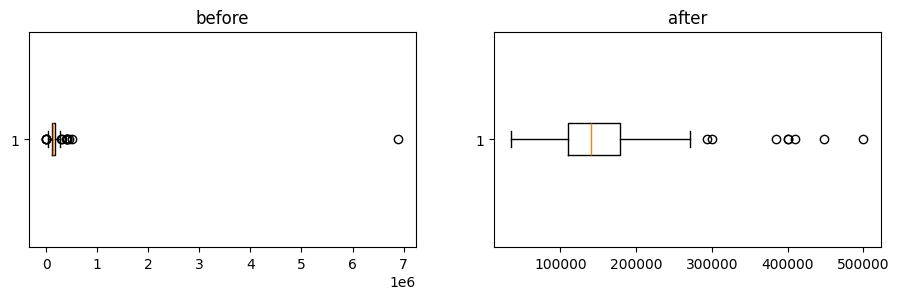

In [5]:
# Rule: keep USD rows with a plausible yearly pay. Look at the counts, then change LOW / HIGH if you disagree.
for lo in (10_000, 15_000, 20_000): print("below", lo, ":", int((pay["normalized_salary"] < lo).sum()))
for hi in (300_000, 500_000, 1_000_000): print("above", hi, ":", int((pay["normalized_salary"] > hi).sum()))
LOW, HIGH = 15_000, 500_000
usd = pay[pay["currency"].eq("USD")]
clean = usd[usd["normalized_salary"].between(LOW, HIGH)].copy()
rules = pd.DataFrame([
    {"problem": "currency not USD or missing", "rule": "drop", "rows_removed": len(pay) - len(usd)},
    {"problem": f"yearly pay outside {LOW:,}-{HIGH:,}", "rule": "drop", "rows_removed": len(usd) - len(clean)},
])
display(rules); print("rows with pay before:", len(pay), "after:", len(clean))
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
ax[0].boxplot(pay["normalized_salary"], vert=False); ax[0].set_title("before")
ax[1].boxplot(clean["normalized_salary"], vert=False); ax[1].set_title("after"); plt.show()

## 3. Hypothesis test: do remote and non-remote data/AI jobs differ in yearly pay?

**What this shows:** a statistical test of one real question. If the p-value is below 0.05 the difference in pay is unlikely to be luck. Also check that both groups have enough rows.

remote_allowed
NaN    1204
1.0     568
Name: count, dtype: int64
data/AI subset: remote n=192 median=138,150 | not remote n=386 median=140,000 | U=35,264 p=0.3433
all postings: remote n=4768 median=113,424 | not remote n=30741 median=77,958 | U=97,207,542 p=7.204e-289


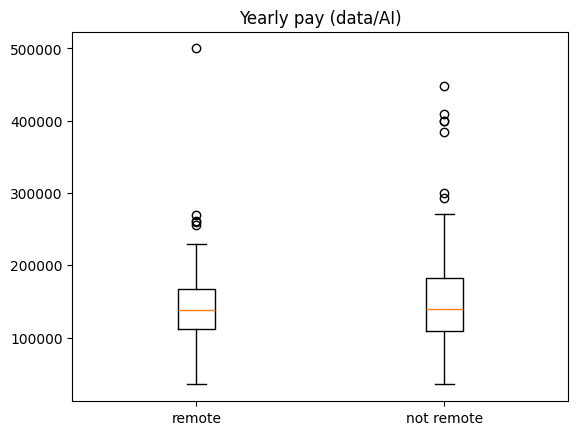

In [6]:
print(sub["remote_allowed"].value_counts(dropna=False))   # empty probably means "not remote": check the counts above
from scipy.stats import mannwhitneyu
def run(data, label):
    rem = data["remote_allowed"].fillna(0).astype(float).eq(1)
    a, b = data.loc[rem, "normalized_salary"], data.loc[~rem, "normalized_salary"]
    res = mannwhitneyu(a, b, alternative="two-sided")
    print(f"{label}: remote n={len(a)} median={a.median():,.0f} | not remote n={len(b)} median={b.median():,.0f} | U={res.statistic:,.0f} p={res.pvalue:.4g}")
    return a, b
a, b = run(clean, "data/AI subset")
# Sensitivity check on ALL postings with plausible USD pay (more rows):
full = df[df["currency"].eq("USD") & df["normalized_salary"].between(LOW, HIGH)]
run(full, "all postings")
plt.boxplot([a, b]); plt.xticks([1, 2], ["remote", "not remote"]); plt.title("Yearly pay (data/AI)"); plt.show()

## 4. EDA: summary statistics, distributions, correlations

**What this shows:** summary numbers, how pay is spread, pay by seniority, and whether views, applies and pay move together.

,views,applies
count,122160.0,23320.0
mean,14.6,10.6
std,85.9,29.0
min,1.0,1.0
25%,3.0,1.0
50%,4.0,3.0
75%,8.0,8.0
max,9975.0,967.0


,normalized_salary
count,578.0
mean,147622.0
std,57136.0
min,35000.0
25%,110000.0
50%,140000.0
75%,178100.0
max,500000.0


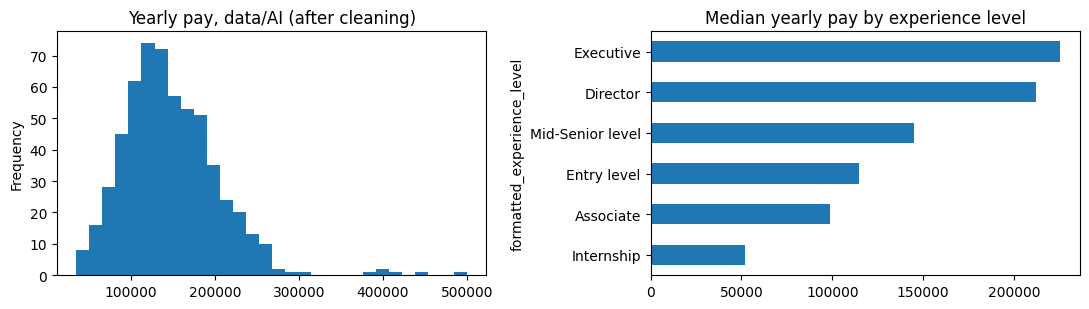

,count,median
formatted_experience_level,,
Associate,36,98750.0
Director,21,212000.0
Entry level,91,114937.5
Executive,7,225000.0
Internship,7,52000.0
Mid-Senior level,291,145000.0


,views,applies,normalized_salary
views,1.00,0.82,0.13
applies,0.82,1.00,0.13
normalized_salary,0.13,0.13,1.00


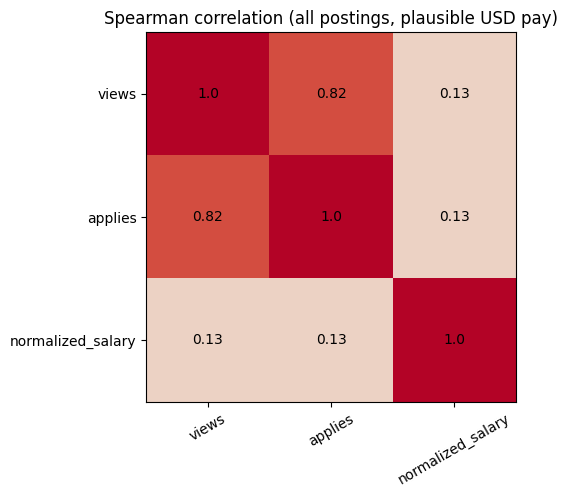

In [7]:
display(df[["views", "applies"]].describe().round(1))
display(clean["normalized_salary"].describe().round(0))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
clean["normalized_salary"].plot.hist(bins=30, ax=ax[0], title="Yearly pay, data/AI (after cleaning)")
(clean.groupby("formatted_experience_level")["normalized_salary"].median().sort_values()
 .plot.barh(ax=ax[1], title="Median yearly pay by experience level")); plt.tight_layout(); plt.show()
display(clean.groupby("formatted_experience_level")["normalized_salary"].agg(["count", "median"]))
ok_pay = df["normalized_salary"].where(df["currency"].eq("USD") & df["normalized_salary"].between(LOW, HIGH))
corr = df[["views", "applies"]].assign(normalized_salary=ok_pay).corr(method="spearman").round(2)
display(corr)
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm"); plt.xticks(range(3), corr.columns, rotation=30); plt.yticks(range(3), corr.index)
for i in range(3):
    for j in range(3): plt.text(j, i, corr.iloc[i, j], ha="center", va="center")
plt.title("Spearman correlation (all postings, plausible USD pay)"); plt.show()

## 5. YOUR RESULTS (edit this cell; these go into `reports/data_quality_report.md`)
- Pay problems found and the rule (copy the table above):
- Remote vs not remote: medians, p-value, and two plain sentences (what it means, and whether the group sizes are big enough):
- Two sentences on the histogram and on pay by experience level:
- Correlation: one sentence: